##ЛР3. Задача классификации

[12 баллов]

## О формате сдачи (все ЛР)

🔷 **<font color='plum'>При решении используйте данный шаблон</font>**

    ✅ Можно добавлять новые ячейки любых типов
    ❌ Не нужно удалять текстовые ячейки c разметкой частей ноутбука и формулировками заданий


🔷 **<font color='plum'>При оценивании задач учитывается код</font>**

    ✅ Задания, в которых необходим код, могут помечаться фразами "Your code here"/"Ваш код" и аналогичными
    ❌ Ответы на вопросы без сопутствующего кода оцениваются в 0 баллов
    ❌ Наличие работоспособного кода в ноутбуке, если на сказано иного, обязательно

🔷 **<font color='plum'>При оценивании задач учитываются выводы</font>**

    ✅ Задания, в которых необходимы выводы, могут помечаться фразами "Вывод"/"Ответ на вопрос"/"Ваш текст" и аналогичными
    ✅ Выводы подразумевают текстовый (письменный, не устный) ответ (можно писать markdown, latex).
    ✅ Сопутствующие изображения, графики, таблички - приветствуются!
    ❌ При отсутствии выводов задание не засчитается на полный балл

🔷 **<font color='plum'>Устная защита</font>**

    ❌❌❌ Если не пройдена устная защита по ЛР, то баллы не начисляются вовсе
    (вопросы устной защиты охватывают лекционный материал и практический материал по заданиям ЛР, список вопросов не публикуется)

## Этапы

<font color='DarkOrange'>**Задание 1 [баллов: 2]:**</font>

Выберите датасет и задачу для него (классификация) - с Kaggle или UCI Machine Learning Repository (https://archive.ics.uci.edu/datasets).
Важно: используйте более новые датасеты, кол-во объектов не менее 100.
Лучше воспользоваться датасетом из предыдущих ЛР.

Выберите (или сгенерите сами) признак, который будет целевым для бинарной классификации.

Используйте LogisticRegression из sklearn. Задайте несколько параметров метода самостоятельно, поясните их назначение и причину выбора конкретных значений.
Используйте несколько метрик, чтоб оценить результаты бинарной классификации (метрики, доступные в sklearn).

*    Используем прошлый датасет: Women in STEM.

In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, roc_curve, precision_recall_curve, confusion_matrix
from sklearn.svm import SVC, OneClassSVM
import warnings
warnings.filterwarnings("ignore", category=UserWarning, module='multiprocessing')

In [2]:
df = pd.read_csv("/Users/devianted/Desktop/Учёба/Сии/women_in_stem.csv")
#df = pd.read_csv("/content/women_in_stem.csv")

In [3]:
df.shape

(500, 6)

In [4]:
df.columns

Index(['Country', 'Year', 'Female Enrollment (%)',
       'Female Graduation Rate (%)', 'STEM Fields', 'Gender Gap Index'],
      dtype='object')

In [5]:
df

,Country,Year,Female Enrollment (%),Female Graduation Rate (%),STEM Fields,Gender Gap Index
0,China,2018,20.4,43.2,Engineering,0.52
1,China,2005,35.6,29.3,Mathematics,0.98
2,China,2005,53.7,32.4,Biology,0.60
3,Germany,2007,65.0,63.6,Mathematics,0.69
4,Canada,2010,54.4,28.8,Engineering,0.74
...,...,...,...,...,...,...
495,Australia,2016,37.2,50.1,Biology,0.91
496,India,2010,59.1,61.2,Engineering,0.66
497,Germany,2010,34.7,34.2,Engineering,0.92
498,Australia,2011,61.2,39.9,Mathematics,0.85


В качестве бинарного признака классификации мы решили взять GAP Index, так как он больше всего подходит.
А как точку переключения берём медиану.
Также, делим наш датасетик на train и test части.

In [6]:
threshold = df["Gender Gap Index"].median()
df["target"] = (df["Gender Gap Index"] >= threshold).astype(int)
df["target"].value_counts()

target
1    254
0    246
Name: count, dtype: int64

In [7]:
years_sorted = np.sort(df["Year"].unique())
cutoff_idx = int(len(years_sorted) * 0.8) if len(years_sorted) > 1 else 1
cutoff_year = years_sorted[min(cutoff_idx, len(years_sorted)-1)]

train_df = df[df["Year"] <= cutoff_year].copy()
test_df  = df[df["Year"] >  cutoff_year].copy()

train_df.shape, test_df.shape, cutoff_year

((409, 7), (91, 7), np.int64(2019))

In [8]:
# признаки и таргет
features = ["Country", "Female Enrollment (%)", "Female Graduation Rate (%)",
            "STEM Fields", "Gender Gap Index"]

X_train = train_df[features]
y_train = train_df["target"]

X_test  = test_df[features]
y_test  = test_df["target"]

# категориальные и числовые признаки
categorical = ["Country", "STEM Fields"]
numeric = ["Female Enrollment (%)", "Female Graduation Rate (%)", "Gender Gap Index"]

# трансформер
preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ("num", StandardScaler(), numeric)
])

model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(C=1.0, solver="lbfgs", max_iter=500))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

acc  = accuracy_score(y_test, y_pred)
prec = precision_score(y_test, y_pred)
rec  = recall_score(y_test, y_pred)
f1   = f1_score(y_test, y_pred)
auc  = roc_auc_score(y_test, y_proba)

acc, prec, rec, f1, auc
confusion_matrix(y_test, y_pred)

array([[46,  0],
       [ 2, 43]])

В модели мы использовали следующие параметры: C, Solver, max_iter; Где:
* C это обратная сила L2 регуляции, и нам нужно это задать, чтобы не было переобучения и модель сходилась
* Solver нужен нам для выбора численного метода для минимизации нашей логистической функции, у нас был взят "lbfgs"
* а последнем мы просто ограничиваем количество шагов нашего оптимизатора во время обучения, чтобы мы могли контролировать сходимость

Для оценки качества мы использовали следующие метрики: accuracy, precision, recall, F1-score, ROC AUC.
* Последние мне пригодятся позже, а также они смотрят на качество модели на всех порогах
* Остальные нам нужны для оценки качества предсказаний

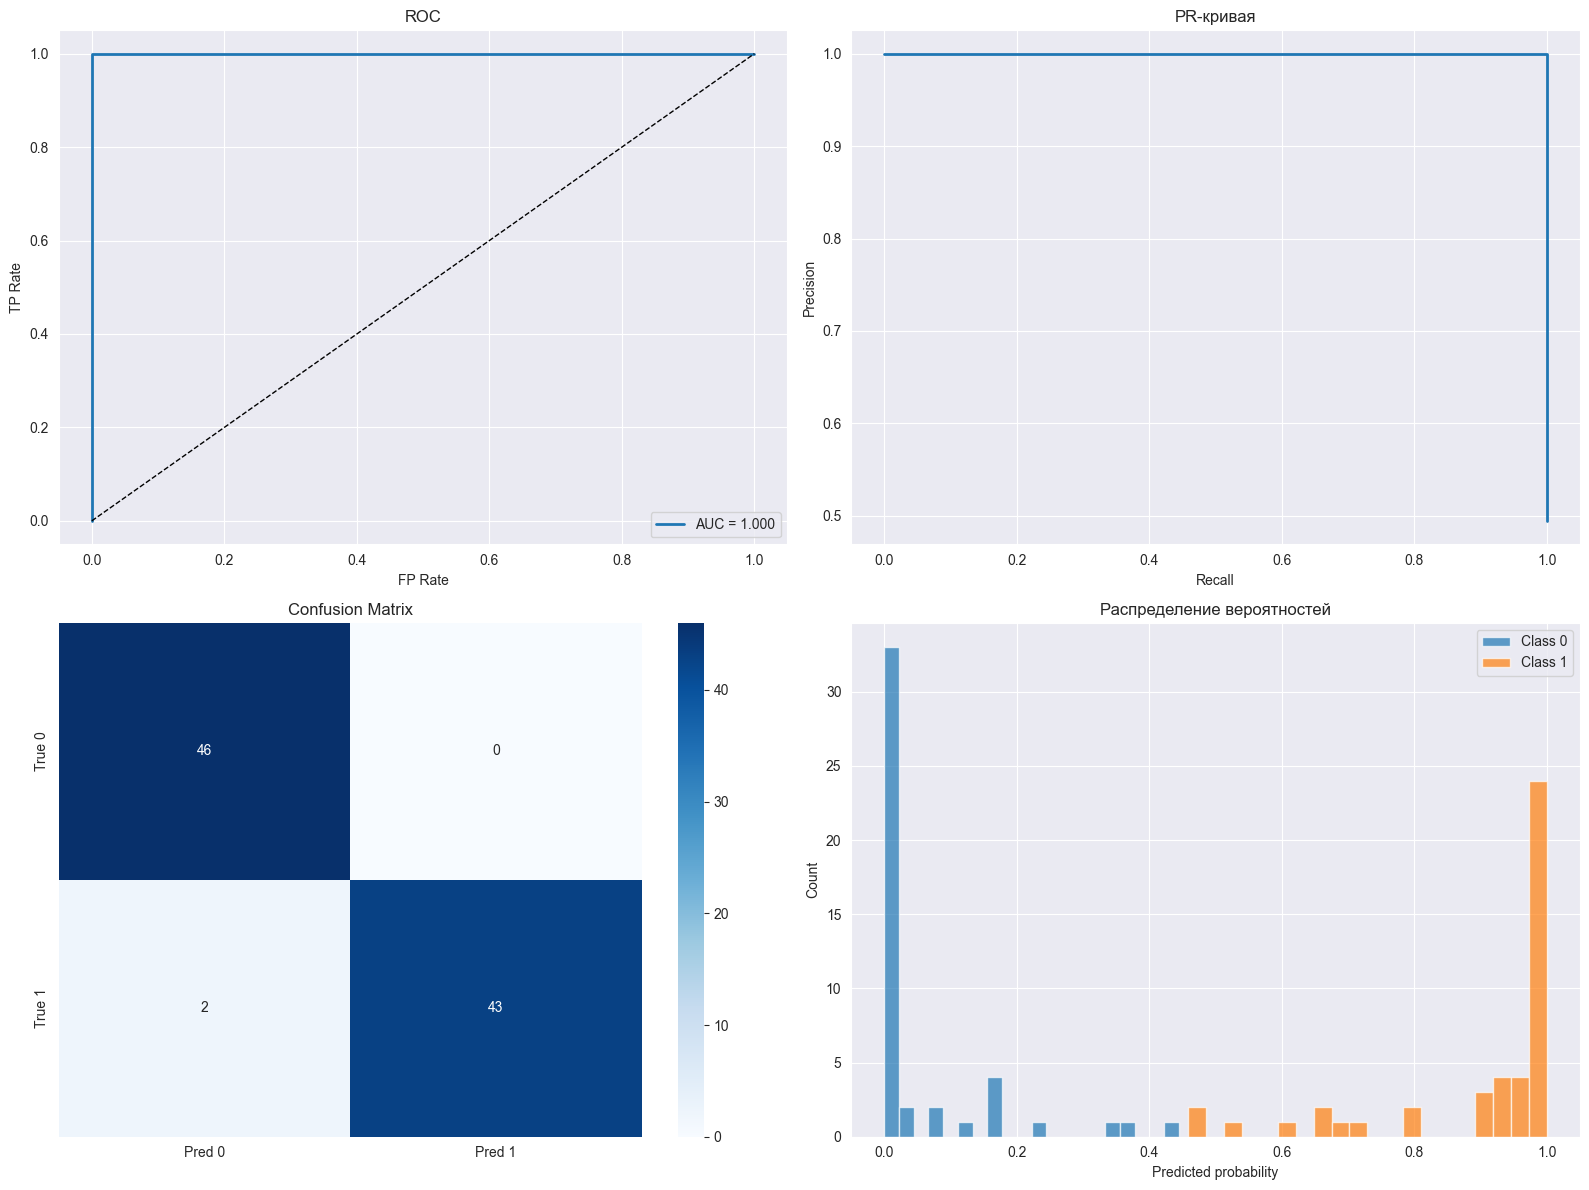

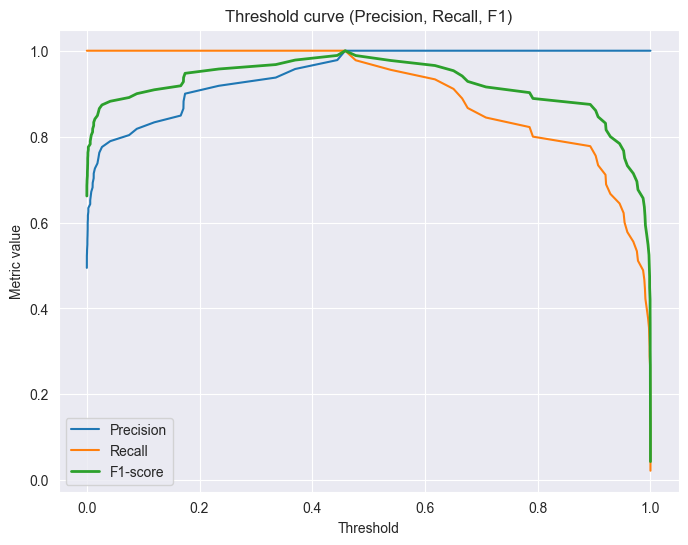

In [11]:
from sklearn.metrics import roc_curve, auc
plt.figure(figsize=(16, 12))

plt.subplot(2, 2, 1)
fpr, tpr, thresholds = roc_curve(y_test, y_proba)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlabel("FP Rate")
plt.ylabel("TP Rate")
plt.title("ROC")
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 2)
precision, recall, thresholds = precision_recall_curve(y_test, y_proba)

plt.plot(recall, precision, linewidth=2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR-кривая")
plt.grid(True)

plt.subplot(2, 2, 3)
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred 0", "Pred 1"],
            yticklabels=["True 0", "True 1"])

plt.title("Confusion Matrix")

plt.subplot(2, 2, 4)
plt.hist(y_proba[y_test == 0], bins=20, alpha=0.7, label="Class 0")
plt.hist(y_proba[y_test == 1], bins=20, alpha=0.7, label="Class 1")

plt.xlabel("Predicted probability")
plt.ylabel("Count")
plt.title("Распределение вероятностей")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

prec, rec, thr = precision_recall_curve(y_test, y_proba)

f1_scores = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1])

plt.figure(figsize=(8, 6))

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.plot(thr, f1_scores, label="F1-score", linewidth=2)

plt.xlabel("Threshold")
plt.ylabel("Metric value")
plt.title("Threshold curve (Precision, Recall, F1)")
plt.legend()
plt.grid(True)
plt.show()

* Мини вывод

Как мы видим, наша модель показала близкие к идеалу результаты (всего 2 ошибки на 91 тест), а метрики качества почти равны 1, что видно по графикам ROC и PR кривой, что значит, что наша модель хорошо различает наш бинарный признка, и признаки хорошо делят наши классы

//мой бред

<font color='DarkOrange'>**Задание 2 [баллов: 2]:**</font>

Выполните бинарную классификацию аналогично предыдущему пункту с использованием SVM (SVC из sklearn, используйте kernel=‘linear’, сами подберите параметр регуляризации С и ответьте на вопрос, может ли/как может SVM учесть несбалансированность классов)


In [12]:
Cs = [0.1, 1, 10]
results = []

for C in Cs:
    svm_model = Pipeline([
        ("prep", preprocess),
        ("clf", SVC(kernel="linear", C=C, probability=True))
    ])

    svm_model.fit(X_train, y_train)

    y_pred_svm = svm_model.predict(X_test)
    y_proba_svm = svm_model.predict_proba(X_test)[:, 1]

    acc  = accuracy_score(y_test, y_pred_svm)
    prec = precision_score(y_test, y_pred_svm)
    rec  = recall_score(y_test, y_pred_svm)
    f1   = f1_score(y_test, y_pred_svm)
    aucv = roc_auc_score(y_test, y_proba_svm)

    results.append([C, acc, prec, rec, f1, aucv])

results_df = pd.DataFrame(results, columns=["C", "Accuracy", "Precision", "Recall", "F1", "ROC AUC"])

# по лучшему C смотрим
best_C = results_df.loc[results_df["F1"].idxmax(), "C"]
best_C
svm_best = Pipeline([
    ("prep", preprocess),
    ("clf", SVC(kernel="linear", C=best_C, probability=True))
])

svm_best.fit(X_train, y_train)

y_pred_svm = svm_best.predict(X_test)
y_proba_svm = svm_best.predict_proba(X_test)[:, 1]

pd.DataFrame(results, columns=["C", "Accuracy", "Precision", "Recall", "F1", "ROC AUC"])

,C,Accuracy,Precision,Recall,F1,ROC AUC
0,0.1,0.956044,0.976744,0.933333,0.954545,0.996135
1,1.0,0.978022,1.000000,0.955556,0.977273,0.999034
2,10.0,0.978022,0.977778,0.977778,0.977778,0.999517


Особо сказать нечего, метрики в некоторых моментах прям очень близки к друг другу.

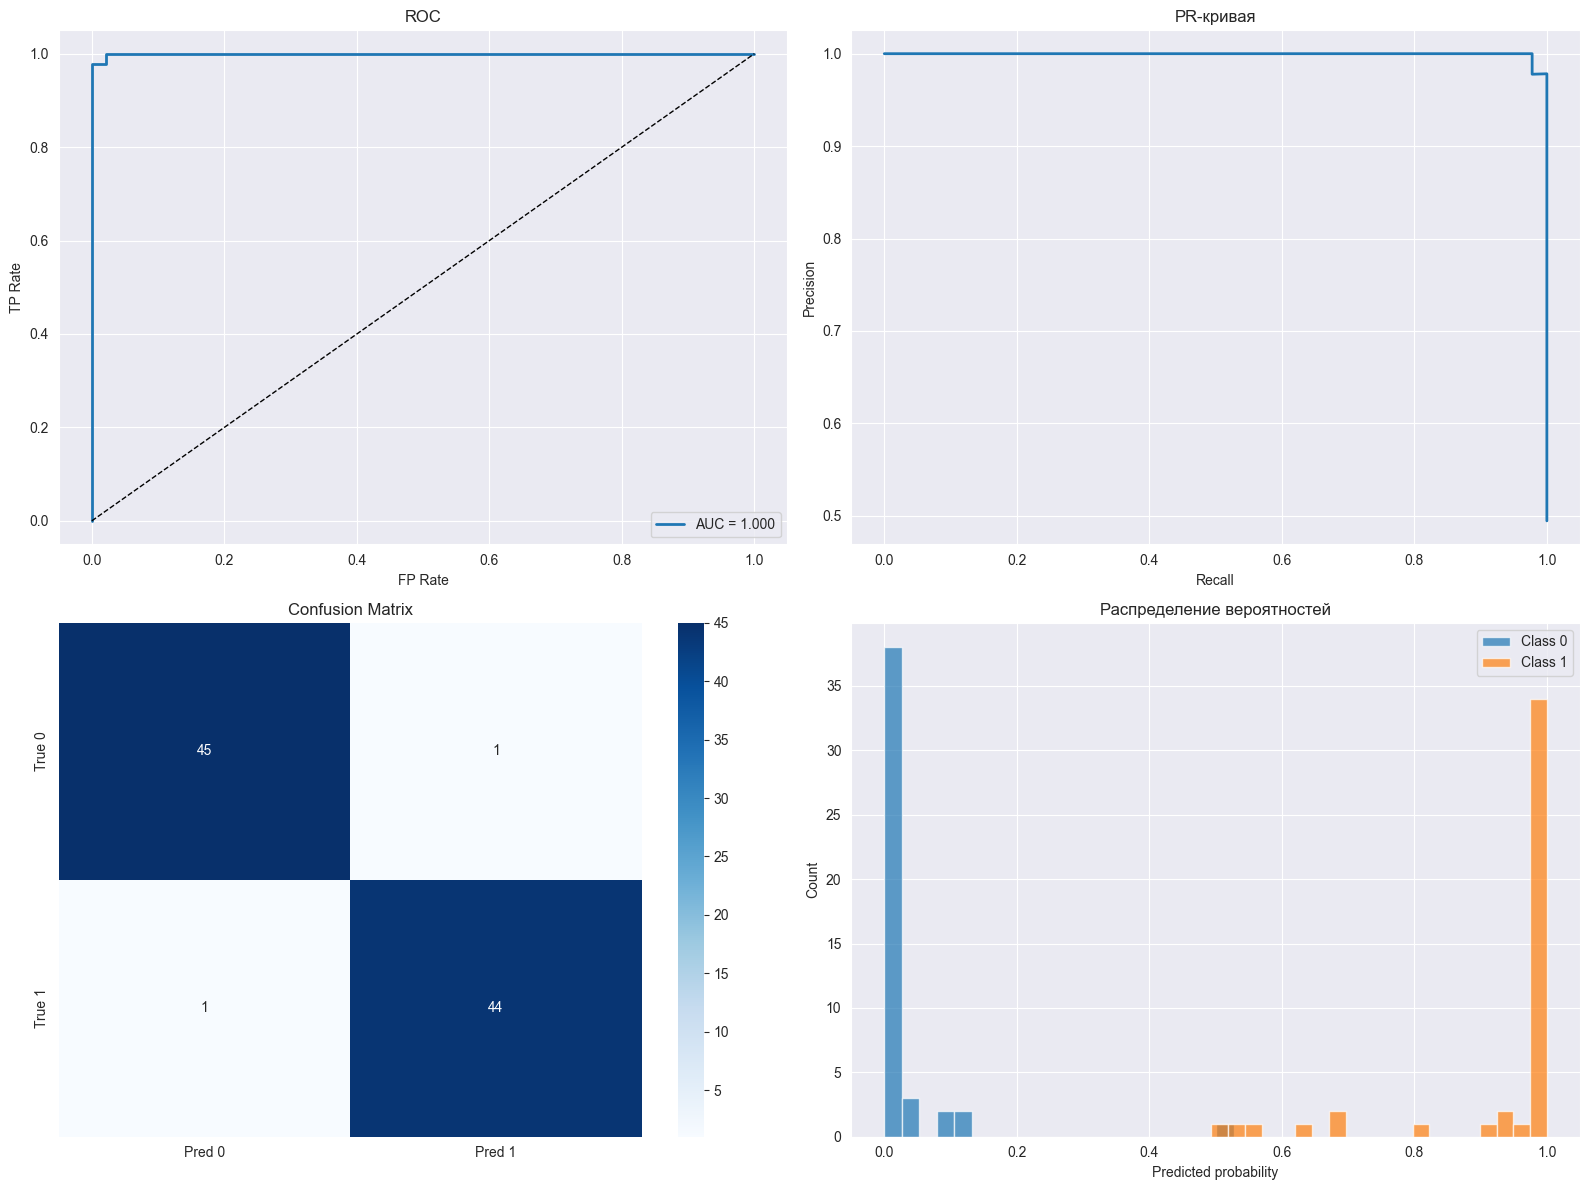

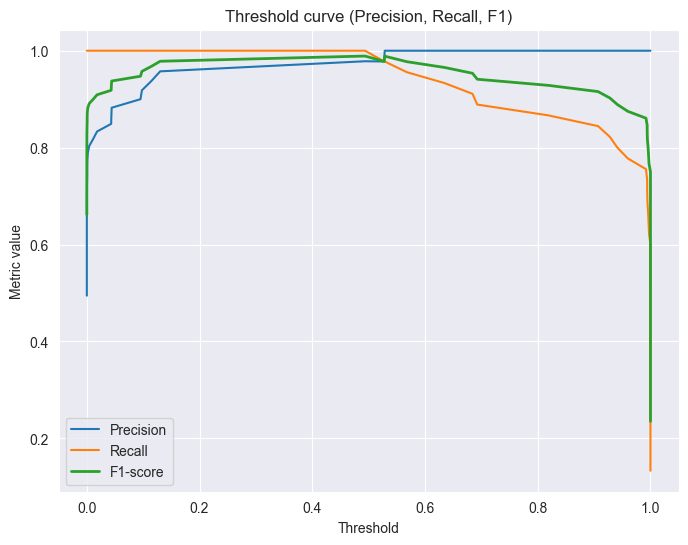

In [13]:
plt.figure(figsize=(16, 12))

plt.subplot(2, 2, 1)
fpr, tpr, thresholds = roc_curve(y_test, y_proba_svm)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, linewidth=2, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
plt.xlabel("FP Rate")
plt.ylabel("TP Rate")
plt.title("ROC")
plt.legend()
plt.grid(True)

plt.subplot(2, 2, 2)
precision, recall, thresholds = precision_recall_curve(y_test, y_proba_svm)

plt.plot(recall, precision, linewidth=2)
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR-кривая")
plt.grid(True)

plt.subplot(2, 2, 3)
cm = confusion_matrix(y_test, y_pred_svm)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred 0", "Pred 1"],
            yticklabels=["True 0", "True 1"])

plt.title("Confusion Matrix")

plt.subplot(2, 2, 4)
plt.hist(y_proba_svm[y_test == 0], bins=20, alpha=0.7, label="Class 0")
plt.hist(y_proba_svm[y_test == 1], bins=20, alpha=0.7, label="Class 1")

plt.xlabel("Predicted probability")
plt.ylabel("Count")
plt.title("Распределение вероятностей")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

prec, rec, thr = precision_recall_curve(y_test, y_proba_svm)

f1_scores = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1])

plt.figure(figsize=(8, 6))

plt.plot(thr, prec[:-1], label="Precision")
plt.plot(thr, rec[:-1], label="Recall")
plt.plot(thr, f1_scores, label="F1-score", linewidth=2)

plt.xlabel("Threshold")
plt.ylabel("Metric value")
plt.title("Threshold curve (Precision, Recall, F1)")
plt.legend()
plt.grid(True)
plt.show()

* Мини вывод

После обучении модели при разных C, особо разницы в метриках не получили (все они крайне близки к 1), что даёт нам понимание что наши данные хорошо линейно разделены.

Также, при сравнении результатов, svm и logistic regression не особо испытывали трудности на наших данных, плюс как видно у нас параметр C не влияет на качество

* Может ли/как может SVM учесть несбалансированность классов

Да, для этого для более редких классов нам нужно будет установить более большие штрафы, для svm нужно будет установить параметр class_weight="balanced", ну или вручную задать для классов вес ошибки.

<font color='DarkOrange'>**Задание 3 [баллов: 6]:**</font>

1. Многоклассовая классификация. Дайте определения для подходов: микро, макро, взвешенный, пообъктный. Выполните расчёты вручную для слайда 43 (на примере любых 3 промежуточных AUC ROC, поясните, как из промежуточных характеристик получаются 4 финальных). В рамках детализации ОЦИФРУЙТЕ ROC: в Excel, отрисуйте линиями в Word или отрисуйте отдельными отрезками Python-кодом (не используйте готовые функции для ROC).
[баллов: 2]

2. Для одного из кейсов (одного класса) введите три порога бинаризации так, чтоб получились различные accuracy, recall, precision. Вычислите эти метрики вручную и сопроводите визуализацией расчёта для recall и precision (см пример из лекции с окружностями разных цветов и радиусов). По трём парам (precision, recall) постройте эскиз PR-кривой. [баллов: 2]

3. Сделайте выводы по результатам расчётом AUC ROC для многоклассовой классификации (какой вариант лучше, почему, объясните падение AUC ROC при переходе к многоклассовым). [баллов: 1]

4. В каких кейсах/доменах следует применять те или иные варианты? Запишите выводы. [баллов: 1]

Для начала объясним смысл подходов:
* micro

Здесь мы складываем TP FP FN по всем классам и считаем метрики оттуда, что по сути используется когда нам важна общая точность по объектам нежели по классам.

* macro

При этом подходе мы считаем метрики для каждого класса отдельно, а потом средне арифметически получаем результат. Иначе говоря это означает что все классы одинаково важны, и редкие тоже к ним приравниваются.

* взвешенный

Тут тоже самое что и с macro, но теперь мы учитываем вес каждого класса, что важно при сильном дисбалансе.

* пообъектный

Тут допускается, что объекты могут иметь несколько меток, и соответственно мы считаем метрику по каждому объекту, а потом усредняем.

Далее, нам нужно сделать расчёты для слайда:



<font color='DarkOrange'>**Задание 4 [баллов: 2]:**</font>

Исследуйте вопрос выбросов/новизны для данных в вашем датасете с использованием OneClassSVM (дайте краткую теоретическую характеристику, используйте готовые решения для получения результатов, сделайте выводы)

Материалы:
1) https://scikit-learn.ru/stable/modules/outlier_detection.html,
2) https://alexanderdyakonov.wordpress.com/, Поиск аномалий

Для начала разберёмся в задаче OneClassSVM.
Оно является методом, которое в представлении пространства признаков, учится находить границы условно нормальных точек, т.е. допустим если у нас есть тренировочная и тестовые выборки, то на тренировочных она условно рисует диапазон нормальных значений (учитывая что мы дали объекты которые МЫ считаем нормальными), а на тестовой мы уже можем увидеть выбиваются ли какие либо значения из этого диапазона.
Эти значения как раз будут называться выбросами или аномалиями.
Так же мы можем настраивать параметры у этого метода, например: nu (приблизительная доля выбросов), gamma (радиус "влияния" точек) и kernel (вид ядра, обычно выбирается ядро RBF).
В sklearn предсказываем так: +1 если нормальный объект и -1 если аномалия.

In [15]:
numeric_oc = ["Female Enrollment (%)", "Female Graduation Rate (%)", "Gender Gap Index"] # смотрим только по числовым признакам

X_train_oc = train_df[numeric_oc]
X_test_oc  = test_df[numeric_oc]

oc_model = make_pipeline(
    StandardScaler(),
    OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)  # думаю 5% будет нормальным количеством для аномалий
)
oc_model.fit(X_train_oc)

train_oc_pred = oc_model.predict(X_train_oc)
test_oc_pred  = oc_model.predict(X_test_oc)

train_df["oc_label"] = train_oc_pred
test_df["oc_label"]  = test_oc_pred

train_df["oc_label"].value_counts(), test_df["oc_label"].value_counts()

(oc_label
  1    387
 -1     22
 Name: count, dtype: int64,
 oc_label
  1    75
 -1    16
 Name: count, dtype: int64)

In [19]:
test_outliers = test_df[test_df["oc_label"] == -1] # аномальные объекты
test_outliers.head()
test_outliers[["Country", "Year", "Female Enrollment (%)",
               "Female Graduation Rate (%)", "Gender Gap Index"]].head(10)

,Country,Year,Female Enrollment (%),Female Graduation Rate (%),Gender Gap Index
9,China,2020,36.7,64.3,0.96
47,Germany,2023,20.9,63.9,0.92
70,Canada,2023,21.0,62.7,0.98
78,India,2022,69.5,31.6,0.74
138,USA,2022,22.1,61.1,0.62
203,India,2023,20.4,28.0,0.75
204,India,2023,21.4,39.7,1.00
217,China,2020,22.4,59.6,0.58
244,China,2023,68.5,28.1,0.93
247,Canada,2023,68.6,64.6,0.61


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


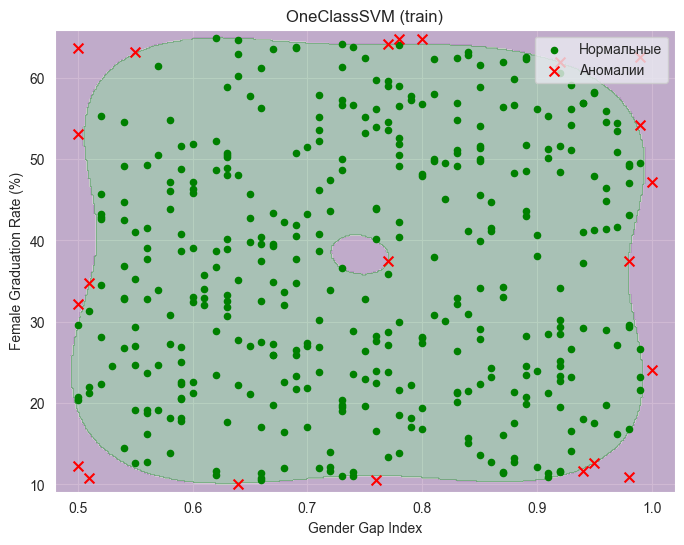

In [28]:
x = "Gender Gap Index"
y = "Female Graduation Rate (%)"

train_2d = train_df[[x, y]]
oc = make_pipeline(
    StandardScaler(),
    OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)
)

oc.fit(train_2d)
xx, yy = np.meshgrid(
    np.linspace(train_2d[x].min() - 0.02, train_2d[x].max() + 0.02, 400),
    np.linspace(train_2d[y].min() - 1,    train_2d[y].max() + 1,    400),
)

grid_points = np.c_[xx.ravel(), yy.ravel()]
Z = oc.predict(grid_points).reshape(xx.shape)

train_pred = oc.predict(train_2d)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, cmap="PRGn", alpha=0.3)
plt.scatter(
    train_2d[x][train_pred == 1],
    train_2d[y][train_pred == 1],
    s=20, color="green", label="Нормальные"
)
plt.scatter(
    train_2d[x][train_pred == -1],
    train_2d[y][train_pred == -1],
    s=50, color="red", marker="x", label="Аномалии"
)

plt.xlabel(x)
plt.ylabel(y)
plt.title("OneClassSVM (train)")
plt.legend()
plt.grid(True)
plt.show()


* Мини вывод

Настроив для нашей тренировочной выборки параметр приближённых выбросов в 5%, у нас получилась следующая картина, на которой мы как раз и видим эти выбросы и область "нормальных" значений, что на самом дела странно выглядит, но похоже на типичные результаты этого метода (некоторые точки незаслужено находятся в своих категориях).
А так, это действительно полезная вещь, помогающая нам сразу обратить внимание на выделяющиеся объекты, а также, можно будет их в дальнейшем обрабатывать по своему.

## Выводы по работе

Выполняя данную лабораторную работу, мы обучили модели logistic regression и svm, также используя бинарную классификацию по признаку GAP index. Учитывая наш датасет, по метрикам мы получили почти идеальное качество, что говорит о хорошей линейной разделимости данных и удачного выбора признака для разбиения.
Помимо этого потыкали подходы для массовой классификации, и посчитали их, особо интересного тут не скажешь.
Также поработали прикольной штукой для выделения аномалий/выбросов, что действительно является интересной темой, ведь там можно много новых интересных дальнейших операций с ними проделать.
Таким образом, поняли как с ошибками предсказаний в общей сути и какие есть варианты подходов по классификации, а анализу их.